# Image captioning with the COCO dataset

In this notebook, we will train an image captioning model on a subset of the COCO dataset.

The work is organised in the following steps:

1. Data loading: we retrieve the images and annotations of the COCO dataset using HuggingFace's `datasets` library
2. Inference of the image embeddings with the `ResNet50` model
3. Tokenization of the COCO captions to prepare our data for training.
4. Definition of the RNN model architecture.
5. Model training.
6. Testing on a new set of data
7. Definition of a new model using an attention mechanism, and visualisation of what it looks at
8. Evaluation of our models with the BLEU score, and comparison of two decoding strategies


## 1. Loading data from a HuggingFace dataset

We will load the data of the `coco_annotation` dataset based on the information from [this dataset](https://huggingface.co/datasets/yerevann/coco-karpathy) (HuggingFace), using the `datasets` library.


In [1]:
# 0.1 — Imports
import os
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import math
import re
import requests

from PIL import Image
from scipy.ndimage import median_filter, sobel
from tqdm import tqdm
from pathlib import Path
from io import BytesIO
from threading import Lock
from tqdm import tqdm

print("TensorFlow", tf.__version__)
print()


I0000 00:00:1792665638.318802    9003 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792665638.576900    9003 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792665640.059716    9003 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0



For the dataset you can do :
from dataset import load_dataset

from datasets import load_dataset
streamed_ds = load_dataset("yerevann/coco-karpathy", split="train", streaming=True)

Or if you venv does not accept this, you can follow my procedure :  

In [2]:

url = "https://huggingface.co/datasets/yerevann/coco-karpathy/resolve/main/data/train-00000-of-00001.parquet"
output = "train.parquet"

response = requests.get(url)
response.raise_for_status()

with open(output, "wb") as f:
    f.write(response.content)

print(f"Dataset téléchargé : {output}")

Dataset téléchargé : train.parquet


In [3]:
df = pd.read_parquet("train.parquet")

print(df.shape)
print(df.columns)
print(df.head())

(82783, 8)
Index(['filepath', 'sentids', 'filename', 'imgid', 'split', 'sentences',
       'cocoid', 'url'],
      dtype='str')
    filepath                                   sentids  \
0  train2014  [787980, 789366, 789888, 791316, 794853]   
1  train2014  [118034, 157682, 159179, 175826, 185540]   
2  train2014  [813979, 814735, 816446, 816950, 817379]   
3  train2014  [636271, 638152, 638287, 638446, 643555]   
4  train2014       [72465, 74946, 76104, 81696, 84192]   

                          filename  imgid  split  \
0  COCO_train2014_000000057870.jpg  40504  train   
1  COCO_train2014_000000384029.jpg  40505  train   
2  COCO_train2014_000000222016.jpg  40506  train   
3  COCO_train2014_000000520950.jpg  40507  train   
4  COCO_train2014_000000069675.jpg  40508  train   

                                           sentences  cocoid  \
0  [A restaurant has modern wooden tables and cha...   57870   
1  [A man preparing desserts in a kitchen covered...  384029   
2  [a big red tele

Make sure to verify where you want the dataset ot be downloaded :"DATASET_PATH" 

In [4]:
EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")
PATCH = 64 # lower this metrics if the download make you crash
DATASET_PATH = "./images" 

# Store paths only, not image arrays
paths = sorted(
    os.path.join(DATASET_PATH, f)
    for f in os.listdir(DATASET_PATH)
    if f.lower().endswith(EXTS)
)

names = []
widths = []
heights = []

for p in tqdm(paths, desc="Reading image metadata"):
    with Image.open(p) as im:
        w, h = im.size

    names.append(os.path.basename(p))
    widths.append(w)
    heights.append(h)

meta = pd.DataFrame({
    "name": names,
    "w": widths,
    "h": heights
})

print(f"{len(paths)} images found")
print(meta[["w", "h"]].describe().round(0))

Reading image metadata: 100%|██████████| 82783/82783 [00:18<00:00, 4497.12it/s]

82783 images found
             w        h
count  82783.0  82783.0
mean     578.0    484.0
std       92.0     97.0
min       59.0     51.0
25%      500.0    426.0
50%      640.0    480.0
75%      640.0    512.0
max      640.0    640.0


Notice that we used the `streaming=True` argument to make sure we don't download the whole dataset.

Let's take a look at the information available through the `Dataset` object.


In [5]:

class COCOKarpathyStream:

    def __init__(self, parquet_path, image_dir):
        self.df = pd.read_parquet(parquet_path)
        self.image_dir = Path(image_dir)

    def __iter__(self):

        for _, row in self.df.iterrows():

            image_path = self.image_dir / row["filename"]

            yield {
                "image": Image.open(image_path).convert("RGB"),
                "filepath": row["filepath"],
                "sentids": row["sentids"],
                "filename": row["filename"],
                "imgid": row["imgid"],
                "split": row["split"],
                "sentences": row["sentences"],
                "cocoid": row["cocoid"],
                "url": row["url"],
            }

We can see a lot of interesting information, notably the exact number of rows and the size of each split (for example, for the train split, 82,783 rows and about 38 MB):


In [6]:
streamed_ds = COCOKarpathyStream(
    "./train.parquet",
    DATASET_PATH
)

### Data split

Let's define a function that splits our data into train, validation and test sets.


In [7]:
NB_TOTAL_ELEMENTS = 82783 # or take length total of picture in a new dataset


def split_data(
    base_dataset, nb_elements=None, percentage=None, split: list[float] = None
):
    if percentage is None and nb_elements is None:
        raise ValueError(
            "At least one variable between 'nb_elements' and 'percentage' must be defined"
        )
    elif percentage is not None and nb_elements is not None:
        raise ValueError(
            "Can't decide which to chose if 'nb_elements' and 'percentage' are defined"
        )
    elif percentage is not None:
        if not 0 < percentage <= 1:
            raise ValueError("'percentage' must verify 0 < percentage <= 1")
        nb_elements = int(NB_TOTAL_ELEMENTS * percentage)

    if nb_elements > NB_TOTAL_ELEMENTS:
        raise ValueError(
            f"Impossible to fetch {nb_elements} rows out of a dataset of {NB_TOTAL_ELEMENTS} rows"
        )

    if not math.isclose(sum(split), 1.0):
        raise ValueError("The sum of the split doesn't amount to 1.0")
    if not len(split) in [2, 3]:
        raise ValueError(
            "There must be either 2 (train+validation) or 3 (train+validation+test) numbers in 'split'"
        )

    output = {
        "train": {
            "last_element": int(split[0] * nb_elements),
            "data": [],
            "to_compute": True,
        },
        "validation": {
            "last_element": int((split[0] + split[1]) * nb_elements),
            "data": [],
            "to_compute": True,
        },
        "test": {
            "last_element": nb_elements,
            "data": [],
            "to_compute": len(split) == 3,
        },
    }

    # Iterating over the dataset, which triggers the download!!
    for i, row in enumerate(base_dataset):
        found = False
        for chosen_ds in output.keys():
            if i < output[chosen_ds]["last_element"]:
                output[chosen_ds]["data"].append(row)
                found = True
                break
        if not found:
            break

    return (elt["data"] for elt in output.values() if elt["to_compute"])

The dataset is downloaded when this function is called, because we used the `streaming=True` option when initialising `streamed_ds`.
This option also lets us avoid downloading the whole dataset if we only iterate over part of it. Indeed, datasets are usually archived and split into several chunks (see [the HuggingFace documentation](https://huggingface.co/docs/datasets/stream) about dataset streaming).

We could even imagine filtering on the metadata and working only with a subset that meets certain conditions, without having to download the data of the discarded elements (we do, however, need the metadata used by the filter).

> **Hint:** when `split` contains 3 proportions, `split_data` returns the train, validation and test sets.

In [8]:
NB_IMAGES = 6500

# 88% of the images for training, 8% for validation and 4% for test
train_ds, validation_ds, test_ds = split_data(streamed_ds, nb_elements=NB_IMAGES, split=(.88, .08, .04))  # TO BE COMPLETED (call split_data on streamed_ds)


Note that using a list rather than a dataset object is a bit lazy, but it remains fairly efficient because this dataset only contains the URLs of the images and not their content (so this information is quick to download).

If the dataset already contained all the images, it would have been better to create the `tensorflow.Dataset` directly, using an operation similar to the one in the `Downloading the data` cell, to avoid duplicating the bulky content of the images.

Let's display the first 2 rows to check the content of our dataset


In [9]:
train_ds[:2]

[{'image': <PIL.Image.Image image mode=RGB size=640x480>,
  'filepath': 'train2014',
  'sentids': array([787980, 789366, 789888, 791316, 794853]),
  'filename': 'COCO_train2014_000000057870.jpg',
  'imgid': 40504,
  'split': 'train',
  'sentences': array(['A restaurant has modern wooden tables and chairs.',
         'A long restaurant table with rattan rounded back chairs.',
         'a long table with a plant on top of it surrounded with wooden chairs ',
         'A long table with a flower arrangement in the middle for meetings',
         'A table is adorned with wooden chairs with blue accents.'],
        dtype=object),
  'cocoid': 57870,
  'url': 'http://images.cocodataset.org/train2014/COCO_train2014_000000057870.jpg'},
 {'image': <PIL.Image.Image image mode=RGB size=640x429>,
  'filepath': 'train2014',
  'sentids': array([118034, 157682, 159179, 175826, 185540]),
  'filename': 'COCO_train2014_000000384029.jpg',
  'imgid': 40505,
  'split': 'train',
  'sentences': array(['A man pr

Let's check how many rows we have in our training set. We expect $0.88 \times$ `NB_IMAGES` of them (e.g. 1760 rows for 2000 images)


In [10]:
len(train_ds)

5720

### Downloading the data

We will now download the images and normalise them directly, using the image processing methods of the `PIL` library to resize them and the preprocessing function associated with the `ResNet` model.

To do so, we first define the preprocessing parameters we will use, namely RGB images of size (224, 224)

> **Hint:** each model of `tf.keras.applications` comes with its own preprocessing function: see the [ResNet section of the Keras documentation](https://keras.io/api/applications/resnet/).

In [11]:
IMG_SIZE = (224, 224)  # ResNet50 standard size
IMG_TYPE = "RGB"
BATCH_SIZE_IMAGES = 8


def image_normalization_method(input):
    # Using ResNet50 specific preprocessing
    # Hint: look up the documentation for tf.keras.applications and search for the resnet50 functions !
    return tf.keras.applications.resnet_v2.preprocess_input(
        input, 
        # data_format=(*IMG_SIZE, 3)
        )

We will now describe our image loading process. The idea is to initialise a tensor containing, for each data row, the URL of the image (the input) and all of its captions (the labels we will compare our predictions with).

We then define the Python function that loads the images from their URLs and applies preprocessing (resizing + normalisation). Note that we could also define this preprocessing in the first layers of our model, with `tensorflow.keras.layers.Resizing` and `tensorflow.keras.layers.Rescaling` layers

> **Hint:** Pillow images have [`convert`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.convert) and [`resize`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.resize) methods.

In [12]:
# The dictionary about failed urls
failed_urls = {}
# The lock protecting it for multi-threaded executions
failed_urls_lock = Lock()

def load_and_preprocess_image(url_tensor):
    # Convert the tensor to a python string
    url = url_tensor.numpy().decode("utf-8")
    
    # Extract the filename from the URL and check locally first
    filename = os.path.basename(url)
    local_path = os.path.join("./images", filename)
    
    img = None
    try:
        if os.path.exists(local_path):
            # Load from local folder if it exists
            img = Image.open(local_path)
        else:
            # Fallback: Download the image if not found locally
            response = requests.get(url, timeout=(5, 20))
            response.raise_for_status()
            img = Image.open(BytesIO(response.content))
            
        # Forces Pillow to load the image data into memory
        img.load()

        # Converts to RGB
        img = img.convert('RGB')

        # Resize to IMG_SIZE
        img = img.resize(IMG_SIZE)
        
    except requests.HTTPError as e:
        with failed_urls_lock:
            failed_urls[url] = f"HTTP error while requesting the url: {e}"
        raise
    except Exception as e:
        with failed_urls_lock:
            failed_urls[url] = f"Error while loading/manipulating the image (local or remote): {e}"
        raise

    try:  
        # Convert to numpy array and normalize
        img_array = image_normalization_method(np.array(img, dtype=np.float32))
    except Exception as e:
        with failed_urls_lock:
            failed_urls[url] = f"Error while normalizing the image: {e}"
        raise
        
    return img_array


def load_data(data_list):
    urls = [item["url"] for item in data_list]
    captions = [item["sentences"][:5] for item in data_list]

    def map_func(url, caption):
        # Calls our preprocessing function (which handles local check + fallback)
        img_tensor = tf.py_function(load_and_preprocess_image, [url], tf.float32)
        # Tells tensorflow about the structure of our tensors
        img_tensor.set_shape((*IMG_SIZE, 3))
        return img_tensor, caption

    # Initializes the dataset with URLs
    dataset = tf.data.Dataset.from_tensor_slices((urls, captions))
    # Processes the data, skipping any errors
    dataset = dataset.map(map_func, num_parallel_calls=tf.data.AUTOTUNE).ignore_errors()
    return dataset

I'd like to draw your attention to a few important details:

- To run a Python function on a `tensorflow.Dataset`, we must use `tf.py_function` and explicitly state the return type of the function passed as an argument. Here, for instance, the `load_and_preprocess_image` function returns `tf.float32` data. We also make the shape of the data explicit using `set_shape`
- The `load_and_preprocess_image` function can raise errors, which is why we use `tf_dataset = tf_dataset.ignore_errors()`. This way, if an error is raised (network error / image reading / image manipulation), the faulty row is skipped and a trace of the error is kept in the `failed_urls` dictionary

We also declare a function that keeps track of the URLs that raised errors and logs a few of them:


In [13]:
def display_errors(nb_errors_shown=3):
    if len(failed_urls) == 0:
        print("Data loaded without any error !")
    else:
        print(f"{len(failed_urls)} errors occured during loading.")
        print(f"Showing {nb_errors_shown} errors")
        i = 0
        for url, error in failed_urls.items():
            if i >= nb_errors_shown:
                break
            print(f"{url} -> {error}\n")
            i += 1

We then create our dataset by calling the function defined above. The operation is lazy, which means it doesn't perform any computation: it only prepares the execution for the first time the data is actually needed (when we really want to read it, for visualisation / training)


#### Small experiments

We will run a few small experiments on a very small dataset, in order to discover some properties of `tensorflow.tensors`


In [14]:
# Example usage with the train_ds
train_tf_ds = load_data(train_ds[:10])  # Limiting to 10 for quick testing

I0000 00:00:1792665681.588847    9003 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6282 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


We can force the loading of the first image with `tf_dataset.take(1)`, which forces the data to be loaded.


In [15]:
for img, cap in train_tf_ds.take(1):
    print(f"Image shape: {img.shape}")
    print(f"Captions: {[caption.decode('utf-8') for caption in cap.numpy()]}")


display_errors()

Image shape: (224, 224, 3)
Captions: ['A restaurant has modern wooden tables and chairs.', 'A long restaurant table with rattan rounded back chairs.', 'a long table with a plant on top of it surrounded with wooden chairs ', 'A long table with a flower arrangement in the middle for meetings', 'A table is adorned with wooden chairs with blue accents.']
Data loaded without any error !


Let's now load the test data. This time, we will add the `tf_dataset.cache()` operation, which stores the content of our dataset in memory. If we had given a path, e.g. `tf_dataset.cache('/tmp/our_data')`, we could have used the hard drive to store the data at the given location.

If we omit the `tf_dataset.cache()` instruction, the downloading and preprocessing of the data will be performed again every time the dataset is iterated over! This default behaviour may seem surprising, but it ensures that the user doesn't run unnecessary operations.

We could also use `tf_dataset.batch()` to batch our data.

> **Hint:** see the [`cache`](https://www.tensorflow.org/api_docs/python/tf/data/Dataset#cache) and [`batch`](https://www.tensorflow.org/api_docs/python/tf/data/Dataset#batch) methods of `tf.data.Dataset`.

In [16]:
# This is instant because it is a lazy operation
test_tf_ds = load_data(test_ds)
# This means that we want to save the preprocessed data the first time it is evaluated
cached_test_tf_ds = test_tf_ds.cache()  # TO BE COMPLETED
# This means that the rows from our final dataset will be grouped in batches of BATCH_SIZE rows.
batched_test_ds = cached_test_tf_ds.batch(BATCH_SIZE_IMAGES)  # TO BE COMPLETED

To force the data to be downloaded and stored in memory, we define the following function, which iterates over the dataset without doing anything other than displaying the progress of the process


In [17]:


def compute_preprocess(ds, ds_name=None):
    if ds_name is not None:
        print(f"Preprocessing and caching the '{ds_name}' dataset")
    for _ in tqdm(ds):
        pass

Finally, let's run the data loading!


In [18]:
# This will take time as it will launch all the preprocess
compute_preprocess(batched_test_ds, "test")

Preprocessing and caching the 'test' dataset


33it [00:00, 87.04it/s]


Now, if we iterate over our dataset again, the operation is instantaneous because the preprocessing has already been done:


In [19]:
for img, labels in batched_test_ds:
  print(img.shape, labels.shape, "\n")

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(8, 224, 224, 3) (8, 5) 

(4, 224, 224, 3) (4, 5) 



Let's also check that we didn't get any errors:


In [20]:
display_errors()

Data loaded without any error !


## Data processing

We will now process our data. The images will be passed through a model to obtain embeddings, and the labels will be tokenized


### 2. Image processing

In keeping with the spirit of the workshop, we will compute the embeddings of all the images with a classification model, from which we will retrieve the output of the last convolutional layer (before the classification).

For a 224x224 image, ResNet50 outputs a 7x7 grid of 2048-dimensional vectors: one vector per region of the image. We will keep this whole grid: our first model will use its average (a single vector per image), and the attention model of section 7 will directly use the 49 vectors. This way, the (slow) computation of the embeddings is done only once.

This is where `BATCH_SIZE_IMAGES` comes into play, since this parameter determines how many images are processed simultaneously by the model.

Let's first define the parameters of our embedding model. We have already configured the input parameters with the image resizing and normalisation. All that's left is to define the output parameters:


In [21]:
EMBEDDINGS_DIMENSION = 2048  # Number of channels of ResNet50's last convolutional layer
EMBEDDING_MAP_DIMENSION = 7 * 7  # Number of regions: ResNet50 outputs a 7x7 grid for a 224x224 image


#### Embedding model

We will use the ResNet50 model to compute our initial embeddings.

> **Hint:** see the [`ResNet50` function](https://keras.io/api/applications/resnet/#resnet50-function) in the Keras documentation, especially its `include_top`, `weights` and `pooling` parameters.

In [22]:
# Load the pre-trained ResNet50 model from Keras applications for Transfer Learning.
# We want to use "imagenet" weights, exclude the top classification layer (include_top)
# and perform NO pooling, so that we keep the whole (7, 7, 2048) output of the last convolutional layer.
# Hint: Check tf.keras.applications.ResNet50 documentation for exact parameter names.

image_embedding_model = tf.keras.applications.ResNet50V2(
    include_top=False,
    weights='imagenet',
    input_shape=(*IMG_SIZE, 3),
    pooling=None,
) 

### 3. Caption processing

We will now use a tokenizer to convert our captions into tokens, so that we can make predictions on them.

Unlike the previous workshop, where we used a tokenizer with a large vocabulary to interpret varied and complex input data (tweets), here we want to minimise the vocabulary size so that our model manages to learn the relationships between the most common words and forms coherent sentences. To do so, we will build its vocabulary from the most common words of the training set.

This way, by reducing the number of words it can predict, we improve the baseline performance of our model, but we limit its full potential.


Let's define the important parameters of our tokenizer:


In [23]:
MAX_VOCABULARY_SIZE = 8000  # Selected based on the dataset
SEQUENCE_MAX_LENGTH = 32  # [START] + 30 words + [END]
NB_SENTENCES_PER_PICTURE = 5  # Based on the dataset's specifications


All the parameters chosen here are arbitrary and try to be consistent with the data we are using. For instance, COCO captions contain about 10 words on average, and fewer than 1 in 1000 exceeds 30 words: those rare captions will simply be truncated.

Let's define the preprocessing method we will use for our text data

> **Hint:** [`str.lower`](https://docs.python.org/3/library/stdtypes.html#str.lower) and [`re.sub`](https://docs.python.org/3/library/re.html#re.sub) are all you need. In a regex, `[^...]` matches any character that is *not* between the brackets.

In [24]:
def preprocess_caption(caption: str):
    # Convert 'caption' to lower case
    ans = caption.lower()  # TO BE COMPLETED

    # Clean up punctuation. Remove everything that isn't a space or a word/alphanumeric character.
    # Hint: Use a regex and the appropriate function from the re module
    ans = re.sub(r'[^a-zA-Z0-9 ]', "", ans)  # TO BE COMPLETED

    return ans

Let's build our vocabulary from the most frequent words of our training set:

> **Hint:** a [`TextVectorization`](https://keras.io/api/layers/preprocessing_layers/text/text_vectorization/) layer builds its vocabulary with its `adapt` method. We use `standardize=None` because we already did our own preprocessing (and the default standardisation would remove the brackets of `[START]` and `[END]`).

In [25]:
all_train_captions = [
    f"[START] {preprocess_caption(caption)} [END]"
    for item in train_ds
    for caption in item["sentences"][:NB_SENTENCES_PER_PICTURE]
]

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_VOCABULARY_SIZE,
    output_sequence_length=SEQUENCE_MAX_LENGTH,
    standardize=None,
)
vectorizer.adapt(all_train_captions)  # TO BE COMPLETED (build the vocabulary of the vectorizer from all_train_captions)

Let's retrieve the parameters of our tokenizer:


In [26]:
vocab = vectorizer.get_vocabulary()

VOCABULARY_SIZE = len(vocab)

# Extract special token IDs from the vocabulary (The .index() function is your best friend)
START_TOKEN_ID = vocab.index('[START]')  # TO BE COMPLETED (index of "[START]")
END_TOKEN_ID = vocab.index('[END]')  # TO BE COMPLETED (index of "[END]")
PAD_TOKEN_ID = 0  # Always 0 for TextVectorization

In [27]:
print(vocab[:20])

['', '[UNK]', np.str_('a'), np.str_('[START]'), np.str_('[END]'), np.str_('on'), np.str_('of'), np.str_('the'), np.str_('in'), np.str_('with'), np.str_('and'), np.str_('is'), np.str_('man'), np.str_('to'), np.str_('sitting'), np.str_('two'), np.str_('an'), np.str_('standing'), np.str_('at'), np.str_('people')]


Let's now define the functions associated with the tokenizer, starting with the decoder:


In [28]:
def decode_caption(token_ids):
    return " ".join(
        vocab[token_id]
        for token_id in token_ids
        if token_id not in {START_TOKEN_ID, END_TOKEN_ID, PAD_TOKEN_ID}
    )

Let's now declare the function that tokenizes our data while keeping the captions grouped by image.

> **Hint:** once adapted, the vectorizer can be called like a function on a list of strings, and returns a tensor.

In [29]:
def tokenize_captions(ds_captions):
    # ds_captions.shape == (BATCH_SIZE_IMAGES, NB_SENTENCES_PER_PICTURE)
    batch_size = ds_captions.shape[0]

    all_captions = []
    for caption_group in ds_captions:
        for caption in caption_group.numpy():
            # Convert tensor of strings to python list of strings
            text = (
                caption.decode("utf-8") if isinstance(caption, bytes) else str(caption)
            )
            # Prepend/append '[START]' and '[END]' to preprocessed captions
            # Don't forget the preprocess_caption function !
            all_captions.append(f"[START] {preprocess_caption(text)} [END]")  # TO BE COMPLETED

    # Tokenize all captions at once for efficiency using the vectorizer layer and cast to numpy
    # Hint: see vectorizer's usage as a function
    tokenized = vectorizer(all_captions).numpy()  # TO BE COMPLETED

    # Reshape back to (batch_size, NB_SENTENCES_PER_PICTURE, SEQUENCE_MAX_LENGTH)
    return tokenized.reshape(batch_size, NB_SENTENCES_PER_PICTURE, SEQUENCE_MAX_LENGTH)

### Computing the full preprocessing

Let's now define a function that:

- infers the embeddings, and flattens the 7x7 grid of each image into a sequence of 49 vectors
- tokenizes and preprocesses the captions
- keeps the relationship between the embeddings and their captions

> **Hint:** both steps only need objects defined above: `image_embedding_model` and `tokenize_captions`. To flatten the grid, see [`tf.reshape`](https://www.tensorflow.org/api_docs/python/tf/reshape): a dimension of `-1` is inferred automatically.

In [30]:
def compute_training_dataset_lists(dataset, dataset_name=None):
    # We use the existing load_data logic but ensure it's batched correctly
    batched_ds = load_data(dataset).batch(BATCH_SIZE_IMAGES).prefetch(tf.data.AUTOTUNE)

    embeddings_list = []
    labels_list = []

    print(f"Starting processing '{dataset_name if dataset_name else ''}'...")
    for images, labels in tqdm(batched_ds):
        # 1. Get image feature maps (ResNet50): (batch, 7, 7, 2048)
        feature_maps = image_embedding_model(images)  # TO BE COMPLETED
        # Flatten the 7x7 grid into a sequence of 49 vectors: (batch, 49, 2048), which makes the next steps easier
        embeddings = tf.reshape(feature_maps, (BATCH_SIZE_IMAGES, EMBEDDING_MAP_DIMENSION, EMBEDDINGS_DIMENSION))  # TO BE COMPLETED (see tf.reshape)
        embeddings_list.append(embeddings)

        # 2. Tokenize captions
        tokenized_batch = tokenize_captions(labels)
        labels_list.append(tokenized_batch)

    return embeddings_list, labels_list


Let's use this function:


In [31]:
train_embeddings, train_labels = compute_training_dataset_lists(train_ds, "train")
validation_embeddings, validation_labels = compute_training_dataset_lists(
    validation_ds, "validation"
)
display_errors()

Starting processing 'train'...


0it [00:00, ?it/s]I0000 00:00:1792665683.799283    9003 cuda_dnn.cc:461] Loaded cuDNN version 92600
715it [01:27,  8.18it/s]


Starting processing 'validation'...


65it [00:07,  8.18it/s]

Data loaded without any error !


In [32]:
print(f"{len(train_embeddings[0])}")
print(f"{len(train_embeddings[0][0])}")
print(f"{len(train_embeddings[0][0][0])}")

8
49
2048


### Average pooling for our first model

Our first model only needs a single vector per image: let's average the 49 vectors of each image. This is exactly what the `pooling="avg"` option of `ResNet50` would have done, but we keep the full embeddings for the attention model of section 7.

> **Hint:** see [`tf.reduce_mean`](https://www.tensorflow.org/api_docs/python/tf/math/reduce_mean) and its `axis` argument.

In [33]:
# (batch, 49, 2048) -> (batch, 2048): average over the regions of the image
train_embeddings_pooled = [tf.math.reduce_mean(batch, axis=1) for batch in train_embeddings]  # TO BE COMPLETED (a list with one tensor of shape (batch, 2048) per batch)
validation_embeddings_pooled = [tf.math.reduce_mean(batch, axis=1) for batch in validation_embeddings]  # TO BE COMPLETED


### Building the final dataset to train our model

We will now build the final dataset needed to train our model. We need a generator that builds on the fly: the embeddings (input), a tensor containing the captions without their last token (input), and the captions without their first token (output) (we train the model to predict the next token).

Each image has 5 captions: rather than duplicating each embedding 5 times in memory (which would quickly fill the RAM with our 49x2048 embeddings), we store the index of the image associated with each caption, and fetch the corresponding embeddings on the fly with `tf.gather`.

> **Hint:** for the caption `[START] a dog runs [END]`, the input is `[START] a dog runs` and the target is `a dog runs [END]`. `all_captions` has the shape `(nb_captions, SEQUENCE_MAX_LENGTH)`: use numpy slicing on its last axis.

In [34]:
import tensorflow as tf
import numpy as np

def dataset_generator(embeddings_list, labels_list, shuffle=False):
    # FIX: Concatenate embeddings on the CPU using NumPy first to save GPU VRAM, 
    # then convert back to a TensorFlow constant.
    all_embeddings = np.concatenate([batch.numpy() for batch in embeddings_list], axis=0)
    all_embeddings = tf.convert_to_tensor(all_embeddings, dtype=tf.float32)
    with tf.device('/GPU:0'):
        all_embeddings = tf.convert_to_tensor(all_embeddings, dtype=tf.float32)
    # One row per caption: (nb_images * NB_SENTENCES_PER_PICTURE, SEQUENCE_MAX_LENGTH)
    all_captions = np.concatenate(
        [batch.reshape(-1, batch.shape[-1]) for batch in labels_list], axis=0
    )
    
    # Index of the image associated with each caption: [0, 0, 0, 0, 0, 1, 1, ...]
    image_indices = np.repeat(np.arange(len(all_embeddings)), NB_SENTENCES_PER_PICTURE)

    print(f"{all_captions.shape=}")
    print(f"{image_indices.shape=}")
    
    caption_inputs = all_captions[:, :-1]   
    caption_targets = all_captions[:, 1:]   

    ans = tf.data.Dataset.from_tensor_slices((image_indices, caption_inputs, caption_targets))

    if shuffle:
        ans = ans.shuffle(buffer_size=len(image_indices), reshuffle_each_iteration=True)

    def fetch_embeddings(batch_image_indices, batch_caption_inputs, batch_caption_targets):
        return (
            {
                "image_input": tf.gather(all_embeddings, batch_image_indices),
                "caption_input": batch_caption_inputs,
            },
            batch_caption_targets,
        )

    return (
        ans.batch(BATCH_SIZE_IMAGES * NB_SENTENCES_PER_PICTURE)
        .map(fetch_embeddings)
        .prefetch(tf.data.AUTOTUNE)
    )

Let's build the generator that produces our model's training dataset


In [35]:
final_train_dataset = dataset_generator(train_embeddings_pooled, train_labels, shuffle=True)
final_validation_dataset = dataset_generator(validation_embeddings_pooled, validation_labels)


all_captions.shape=(28600, 32)
image_indices.shape=(28600,)
all_captions.shape=(2600, 32)
image_indices.shape=(2600,)


## 4. Defining our NLP model

We will now define a model that takes our embeddings as input and whose goal is to predict our captions.

> **Hint:** the layers you need are [`Dense`](https://keras.io/api/layers/core_layers/dense/), [`Embedding`](https://keras.io/api/layers/core_layers/embedding/) and [`LSTM`](https://keras.io/api/layers/recurrent_layers/lstm/) (look at the `initial_state` argument of its call). The model itself is built with [`tf.keras.Model`](https://keras.io/api/models/model/), by giving it its inputs and its output (functional API).

In [36]:
import tensorflow as tf

# Hyperparameters
CAPTION_EMBEDDINGS_DIMENSION = 256
HIDDEN_UNITS = 256

# 1. Image Embedding Input
# Shape: (EMBEDDINGS_DIMENSION,)
image_input = tf.keras.layers.Input(shape=(EMBEDDINGS_DIMENSION,), name="image_input")
# Map image embedding to the HIDDEN_UNITS space using a Dense layer and ReLU activation
image_dense = tf.keras.layers.Dense(HIDDEN_UNITS, activation='relu', name="image_dense")(image_input)  # TO BE COMPLETED

# 2. Caption Input (for Teacher Forcing during training)
# Shape: (None,) to allow for variable sequence lengths in batches
caption_input = tf.keras.layers.Input(shape=(None,), name="caption_input")
# Project vocabulary token indices to dense embedding space of size CAPTION_EMBEDDINGS_DIMENSION
# Hint: use tf.keras.layers.Embedding with correct VOCABULARY_SIZE
caption_embedding = tf.keras.layers.Embedding(VOCABULARY_SIZE, CAPTION_EMBEDDINGS_DIMENSION, name="caption_embed")(caption_input)  # TO BE COMPLETED
caption_embedding = tf.keras.layers.Dropout(0.3, name="caption_embed_dropout")(caption_embedding)  # type: ignore

# 3. Recurrent Layer (LSTM)
# We use the image dense representations to initialize the LSTM states [h, c]
lstm_layer = tf.keras.layers.LSTM(HIDDEN_UNITS, return_sequences=True, name="lstm")
# Connect the caption embedding to the LSTM. Pass initial_state as [image_dense, image_dense]
x = lstm_layer(caption_embedding, initial_state=[image_dense, image_dense])  # TO BE COMPLETED
x = tf.keras.layers.Dropout(0.3, name="lstm_dropout")(x)

# 4. Output Layer
# A probability for each word of the vocabulary
output = tf.keras.layers.Dense(len(vocab), activation='softmax', name="output")(x)  # TO BE COMPLETED

# Define the final Keras Model listing all inputs and final output
# Hint: Model inputs are both image_input and caption_input
nlp_model = tf.keras.Model(inputs=[image_input, caption_input], outputs=output)  # TO BE COMPLETED

nlp_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ caption_input       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ caption_embed       │ (None, None, 256) │  1,960,960 │ caption_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_input         │ (None, 2048)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ caption_embed_drop… │ (None, None, 256) │          0 │ caption_embed[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_dense (Dense) │ (None, 256)       │    524,544 │ image_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, None, 256) │    525,312 │ caption_embed_dr… │
│                     │                   │            │ image_dense[0][0… │
│                     │                   │            │ image_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_dropout        │ (None, None, 256) │          0 │ lstm[0][0]        │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, None,      │  1,968,620 │ lstm_dropout[0][… │
│                     │ 7660)             │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,979,436 (19.00 MB)

 Trainable params: 4,979,436 (19.00 MB)

 Non-trainable params: 0 (0.00 B)

### Ignoring the padding

Our captions are padded with `0`s up to `SEQUENCE_MAX_LENGTH` tokens, but a COCO caption only contains about 10 words. Let's measure which proportion of the targets our model has to predict are actually padding tokens:

In [37]:
all_targets = np.concatenate(
    [batch.reshape(-1, batch.shape[-1])[:, 1:] for batch in train_labels], axis=0
)
print(f"Proportion of padding tokens in the targets: {np.mean(all_targets == PAD_TOKEN_ID):.1%}")


Proportion of padding tokens in the targets: 63.1%


Most of the targets are padding! With the default loss and accuracy, the model is rewarded for predicting padding after the end of the caption, which is trivial: the accuracy looks great right from the first epoch, while telling us nothing about the quality of the captions, and the loss is dominated by these meaningless positions.

We therefore define a masked loss and a masked accuracy, which only take into account the positions where the target is a real token.

Note that we don't need to mask the input of the LSTM: the padding is at the end of the sequence and the LSTM reads from left to right, so the padding tokens can't influence the predictions made on the real words.

> **Hint:** [`tf.not_equal`](https://www.tensorflow.org/api_docs/python/tf/math/not_equal), [`tf.cast`](https://www.tensorflow.org/api_docs/python/tf/cast) and [`tf.reduce_sum`](https://www.tensorflow.org/api_docs/python/tf/math/reduce_sum) are your friends. `masked_accuracy` follows exactly the same logic.

In [38]:
@tf.keras.utils.register_keras_serializable()
def masked_loss(y_true, y_pred):
    # Loss for every position of every caption: shape (batch_size, sequence_length)
    loss = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    # 1 where the target is a real token, 0 where it is padding
    mask = tf.cast(tf.not_equal(y_true, PAD_TOKEN_ID), tf.float32)  # TO BE COMPLETED
    # Average over the real tokens only
    # TO BE COMPLETED:
    return tf.reduce_sum(mask * loss) / tf.reduce_sum(mask)


@tf.keras.utils.register_keras_serializable()
def masked_accuracy(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int64)
    is_correct = tf.cast(tf.equal(tf.argmax(y_pred, axis=-1), y_true), tf.float32)
    mask = tf.cast(tf.not_equal(y_true, PAD_TOKEN_ID), tf.float32)
    return tf.reduce_sum(is_correct * mask) / tf.reduce_sum(mask)


Let's use the Adam optimizer with our masked loss to train our model

In [39]:
# Compile the model. Specify an optimizer and the loss function.
# Hint: use the masked loss and accuracy defined above.
nlp_model.compile(optimizer='adam', loss=masked_loss, metrics=[masked_accuracy])

## 5. Model training

We now launch the training on our `final_train_dataset`. The model will learn to predict the next token given the image embedding and the previous tokens (Teacher Forcing).


Let's define the model's training parameters

> **Hint:** to stop the training when the validation loss stops improving, see the [`EarlyStopping`](https://keras.io/api/callbacks/early_stopping/) callback.

In [40]:
EPOCHS = 50

history = nlp_model.fit(
    final_train_dataset,
    validation_data=final_validation_dataset,
    epochs=EPOCHS,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        patience=3,
        restore_best_weights=True
    )],
)

Epoch 1/50
715/715 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - loss: 4.6499 - masked_accuracy: 0.2700 - val_loss: 4.0363 - val_masked_accuracy: 0.3409
Epoch 2/50
715/715 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 3.7352 - masked_accuracy: 0.3477 - val_loss: 3.5717 - val_masked_accuracy: 0.3787
Epoch 3/50
715/715 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 3.3485 - masked_accuracy: 0.3836 - val_loss: 3.3580 - val_masked_accuracy: 0.4021
Epoch 4/50
715/715 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 3.1205 - masked_accuracy: 0.4024 - val_loss: 3.2394 - val_masked_accuracy: 0.4141
Epoch 5/50
715/715 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 2.9603 - masked_accuracy: 0.4166 - val_loss: 3.1818 - val_masked_accuracy: 0.4234
Epoch 6/50
715/715 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 2.8326 - masked_accuracy: 0.4272 - val_loss: 3.1445 - val_masked_accuracy: 0.4296
Epoch 7/50
715/715 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 2.7277 - masked_accuracy: 0.4363 - val_loss: 3.1289 - val_masked_accuracy:

### Learning curves of our model

Let's plot the learning curves of our model:


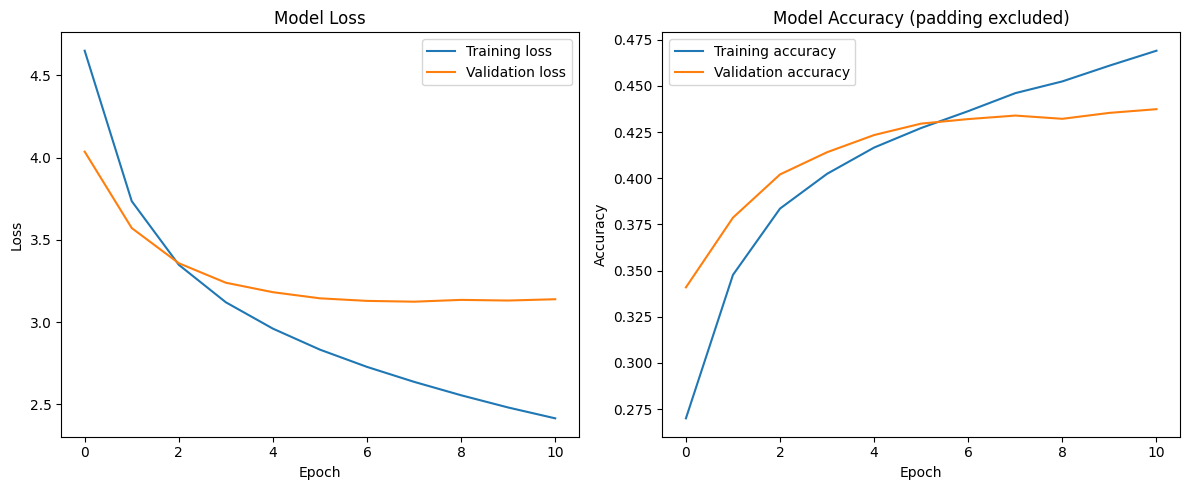

In [41]:
import matplotlib.pyplot as plt


def plot_learning_curves(history):
    plt.figure(figsize=(12, 5))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(history.history["loss"], label="Training loss")
    plt.plot(history.history["val_loss"], label="Validation loss")
    plt.title("Model Loss")
    plt.legend()
    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    # Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(history.history["masked_accuracy"], label="Training accuracy")
    plt.plot(history.history["val_masked_accuracy"], label="Validation accuracy")
    plt.title("Model Accuracy (padding excluded)")
    plt.legend()
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.tight_layout()
    plt.show()


plot_learning_curves(history)


What do you observe on the learning curves? How could we reduce overfitting, and which of these options are compatible with our pipeline, given that the image embeddings are computed only once?

<em>TO BE COMPLETED</em>

## 6. Predictions of our model

We will now build the complete model, which takes an image as input, computes its embeddings with ResNet50 and produces the caption, which we then detokenize


In [42]:

def load_image(image_url):
    # Download the image and apply the same preprocessing as during training
    response = requests.get(image_url, timeout=(5, 20))
    response.raise_for_status()
    img = Image.open(BytesIO(response.content)).convert(IMG_TYPE).resize(IMG_SIZE)
    img_array = image_normalization_method(np.array(img, dtype=np.float32))
    return img, np.expand_dims(img_array, axis=0)  # Add batch dimension


def embed_image(img_array):
    # Same processing as in compute_training_dataset_lists: (batch, 7, 7, 2048) -> (batch, 49, 2048)
    feature_maps = image_embedding_model(img_array, training=False)
    return tf.reshape(feature_maps, (-1, EMBEDDING_MAP_DIMENSION, EMBEDDINGS_DIMENSION)).numpy()


def greedy_decode(model, img_embed):
    # Keras can't mix tensorflow tensors and numpy arrays in the inputs of a model
    img_embed = np.asarray(img_embed)

    # Start with our starting special token
    current_tokens = [START_TOKEN_ID]  # TO BE COMPLETED

    # The model was trained on sequences of at most SEQUENCE_MAX_LENGTH - 1 input tokens
    for _ in range(SEQUENCE_MAX_LENGTH - 1):
        token_tensor = np.array([current_tokens])
        # Calling the model directly is much faster than model.predict for a single small input
        predictions = model([img_embed, token_tensor], training=False).numpy()

        # Get the last predicted token in the output sequence using argmax
        # Hint: Predictions shape is (1, sequence_len, VOCABULARY_SIZE). We want the argmax of the last token: predictions[0, -1, :]
        next_token = np.argmax(predictions[0, -1, :])  # TO BE COMPLETED  # type: ignore

        current_tokens.append(next_token)

        # Check: Stop if we hit our ending special token
        if next_token == END_TOKEN_ID:  # TO BE COMPLETED
            break

    return current_tokens


def generate_caption(image_url, decode_method=greedy_decode):
    # 1. Load and preprocess the image
    img, img_array = load_image(image_url)

    # 2. Get image embedding, averaged over the regions of the image as for the training data
    img_embed = embed_image(img_array).mean(axis=1)

    # 3. Generate the tokens of the caption (greedy search by default)
    tokens = decode_method(nlp_model, img_embed)
    print(f"predicted_tokens: {decode_caption(tokens)}")

    # 4. Decode the tokens
    return decode_caption(tokens), img


Let's now define a function that displays a subplot with the predicted captions of several images


In [43]:
def plot_predictions(urls, subplot_dim, inference_method=generate_caption):
    if len(subplot_dim) != 2:
        raise ValueError(
            f"subplot_dim must contain exactly two items, got {subplot_dim}"
        )
    if subplot_dim[0] * subplot_dim[1] != len(urls):
        raise ValueError(
            f"We have a mismatch between the subplot_dim and the number of urls : {subplot_dim[0]} * {subplot_dim[1]} != {len(urls)}"
        )

    plt.figure(figsize=(15, 10))
    for i, url in enumerate(urls):
        caption, img = inference_method(url)
        plt.subplot(*subplot_dim, i + 1)
        plt.imshow(img)
        # Use xlabel instead of title to prevent vertical overlap
        plt.xlabel(caption, fontsize=10)
        plt.xticks([])
        plt.yticks([])

    plt.tight_layout()
    plt.show()

Let's try it on the first 6 images:


predicted_tokens: a bathroom with a sink and a sink and a mirror
predicted_tokens: a desk with a laptop computer and a keyboard
predicted_tokens: a kitchen with a refrigerator and a refrigerator and a refrigerator
predicted_tokens: a desk with a computer monitor and a laptop
predicted_tokens: a bunch of boats are on a beach
predicted_tokens: a man riding a motorcycle down a road
predicted_tokens: a man riding a motorcycle down a road
predicted_tokens: a small white plate with a sandwich and a cup of coffee
predicted_tokens: a plate with a bunch of vegetables and a cup of fruit
predicted_tokens: a man holding a hot dog in a bun
predicted_tokens: a vase filled with flowers in a vase
predicted_tokens: a motorcycle parked in a field with a lot of trees
predicted_tokens: a man riding a motorcycle down a street
predicted_tokens: a man riding a motorcycle down a street
predicted_tokens: a bunch of different types of luggage
predicted_tokens: a train is on the tracks near a building


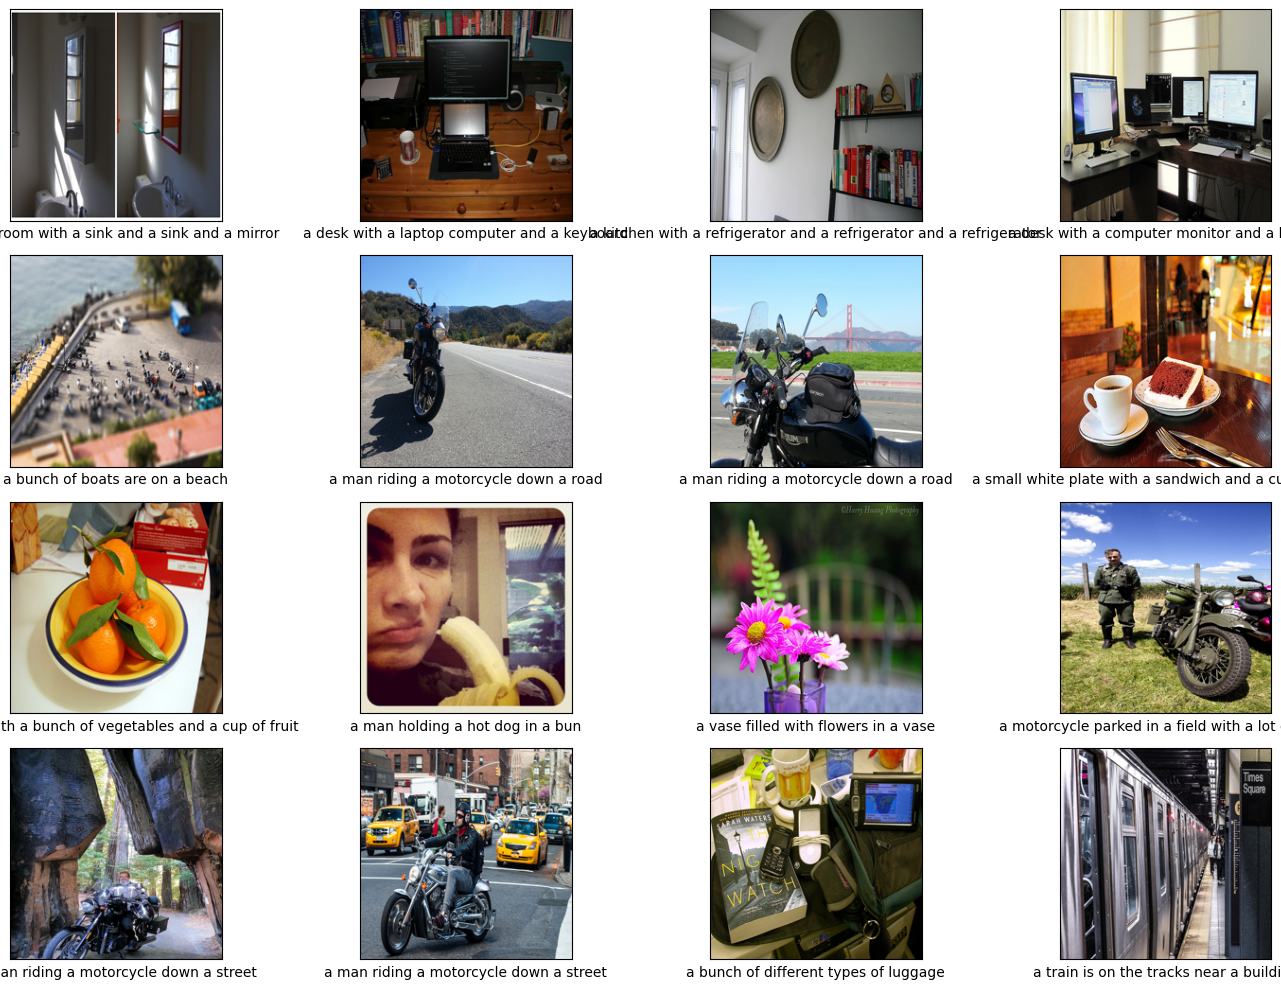

In [44]:
# Let's test it on a sample from the test set
N = 0
plot_predictions([elt["url"] for elt in test_ds[N : N + 16]], (4, 4))

## 7. Let's add some attention to all this!

Given the disastrous performance of your models (mine is amazing considering it was trained on a tiny dataset), we will try adding an attention layer to our model.

Good news: we kept the embeddings of our images before averaging them! Each image is described by 49 vectors, one per region, which is exactly what an attention layer needs: when generating each word, the model will be able to choose which regions of the image to focus on. No need to compute anything again, we can directly build the datasets of our new model:

In [45]:
final_train_dataset2 = dataset_generator(train_embeddings, train_labels, shuffle=True)
final_validation_dataset2 = dataset_generator(validation_embeddings, validation_labels)

all_captions.shape=(28600, 32)
image_indices.shape=(28600,)
all_captions.shape=(2600, 32)
image_indices.shape=(2600,)


### New model with attention

The new architecture of our model is the following:

Compared to our first model:

- the image is now a sequence of 49 vectors (one per region of the image), each one projected into `HIDDEN_UNITS` dimensions by a `Dense` layer (a `Dense` layer applied to a 3D tensor acts on its last axis);
- the LSTM is initialised with the average of these 49 vectors, see [`GlobalAveragePooling1D`](https://keras.io/api/layers/pooling_layers/global_average_pooling1d/);
- a [`MultiHeadAttention`](https://keras.io/api/layers/attention_layers/multi_head_attention/) layer lets each word (the *query*) look at the 49 regions of the image (the *keys* and *values*). With `return_attention_scores=True`, it also returns the attention weights.

In [46]:
# Hyperparameters
CAPTION_EMBEDDINGS_DIMENSION = 256
HIDDEN_UNITS = 256


# 1. Image input: (IMAGE_N_PATCHES, IMAGE_FEATURE_DIM) = (49, 2048)
image_input2 = tf.keras.layers.Input(
    shape=(EMBEDDING_MAP_DIMENSION, EMBEDDINGS_DIMENSION), name="image_input"
)

# Project each of the 49 spatial positions from 2048 → HIDDEN_UNITS
# so that the image and language representations live in the same space.
image_features2 = tf.keras.layers.Dense(HIDDEN_UNITS, name="image_features2", activation='relu')(image_input2)  # TO BE COMPLETED, shape: (49, HIDDEN_UNITS)

image_features2 = tf.keras.layers.Dropout(0.1, name="postdense_image_dropout")(image_features2)
# Average over spatial positions to get a single vector for LSTM initialisation.
# The attention layer will later recover the fine-grained spatial information.
image_state2 = tf.keras.layers.GlobalAveragePooling1D(name="image_state2")(image_features2)  # TO BE COMPLETED, shape: (HIDDEN_UNITS,)

# 2. Caption Input (for Teacher Forcing during training)
caption_input2 = tf.keras.layers.Input(shape=(None,), name="caption_input")
caption_embedding2 = tf.keras.layers.Embedding(VOCABULARY_SIZE, CAPTION_EMBEDDINGS_DIMENSION, name="caption_embedding2")(caption_input2)
caption_embedding2 = tf.keras.layers.Dropout(0.3, name="caption_dropout2")(caption_embedding2)

# 3. LSTM initialised from the mean image state
lstm_layer2 = tf.keras.layers.LSTM(HIDDEN_UNITS, return_sequences=True, name="lstm_layer2")
x2 = lstm_layer2(caption_embedding2, initial_state=[image_state2, image_state2])
x2 = tf.keras.layers.Dropout(0.3, name="x_dropout2")(x2)

# 4. Cross-attention: each output token (query) attends over the 49 image
# positions (key/value). This is the core of visual attention — the model
# learns which region to focus on when generating each word.
# use_causal_mask is NOT needed here because the keys/values are image features,
# not future caption tokens.
# We also retrieve the attention scores, to visualise them later on.
# Use 2 heads, a key_dim of 32 and a dropout of 0.1
x_attn, attention_scores2 = tf.keras.layers.MultiHeadAttention(
    num_heads=2,
    key_dim=32,
    dropout=.1,
    name="attention2",
)(query=x2, value=image_features2, key=image_features2, return_attention_scores=True)  # TO BE COMPLETED
# Residual connection + LayerNorm: stabilises training.
x2 = tf.keras.layers.Add(name="addition2")([x2, x_attn])
x2 = tf.keras.layers.LayerNormalization(name="norm2")(x2)

x2 = tf.keras.layers.Dropout(0.1, name="postattention_image_dropout")(x2)

# 5. Output Layer
output2 = tf.keras.layers.Dense(VOCABULARY_SIZE, activation="softmax", name="output2")(x2)

# Define the final model
nlp_model2 = tf.keras.Model(inputs=[image_input2, caption_input2], outputs=output2)
# Same layers (and therefore same weights) as nlp_model2, but also outputs the attention scores.
# It is only used to visualise the attention, never trained directly.
attention_model2 = tf.keras.Model(
    inputs=[image_input2, caption_input2], outputs=[output2, attention_scores2]
)

nlp_model2.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 49, 2048)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ caption_input       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_features2     │ (None, 49, 256)   │    524,544 │ image_input[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ caption_embedding2  │ (None, None, 256) │  1,960,960 │ caption_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ postdense_image_dr… │ (None, 49, 256)   │          0 │ image_features2[… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ caption_dropout2    │ (None, None, 256) │          0 │ caption_embeddin… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_state2        │ (None, 256)       │          0 │ postdense_image_… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_layer2 (LSTM)  │ (None, None, 256) │    525,312 │ caption_dropout2… │
│                     │                   │            │ image_state2[0][… │
│                     │                   │            │ image_state2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ x_dropout2          │ (None, None, 256) │          0 │ lstm_layer2[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention2          │ [(None, None,     │     65,984 │ postdense_image_… │
│ (MultiHeadAttentio… │ 256), (None, 2,   │            │ x_dropout2[0][0], │
│                     │ None, None)]      │            │ postdense_image_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ addition2 (Add)     │ (None, None, 256) │          0 │ x_dropout2[0][0], │
│                     │                   │            │ attention2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ norm2               │ (None, None, 256) │        512 │ addition2[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ postattention_imag… │ (None, None, 256) │          0 │ norm2[0][0]       │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output2 (Dense)     │ (None, None,      │  1,968,620 │ postattention_im… │
│                     │ 7660)             │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,045,932 (19.25 MB)

 Trainable params: 5,045,932 (19.25 MB)

 Non-trainable params: 0 (0.00 B)

Let's compile it:

In [47]:
nlp_model2.compile(optimizer='adam', loss=masked_loss, metrics=[masked_accuracy])

Let's train it:

In [48]:
history2 = nlp_model2.fit(
    final_train_dataset2,
    validation_data=final_validation_dataset2,
    epochs=EPOCHS,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)],
)

Epoch 1/50
715/715 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - loss: 3.9321 - masked_accuracy: 0.3365 - val_loss: 3.3591 - val_masked_accuracy: 0.4030
Epoch 2/50
715/715 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - loss: 3.0076 - masked_accuracy: 0.4188 - val_loss: 3.1820 - val_masked_accuracy: 0.4271
Epoch 3/50
715/715 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - loss: 2.6842 - masked_accuracy: 0.4485 - val_loss: 3.1732 - val_masked_accuracy: 0.4301
Epoch 4/50
715/715 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - loss: 2.4637 - masked_accuracy: 0.4686 - val_loss: 3.2353 - val_masked_accuracy: 0.4323
Epoch 5/50
715/715 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - loss: 2.2975 - masked_accuracy: 0.4852 - val_loss: 3.2786 - val_masked_accuracy: 0.4324
Epoch 6/50
715/715 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - loss: 2.1660 - masked_accuracy: 0.5007 - val_loss: 3.3244 - val_masked_accuracy: 0.4289
Epoch 7/50
715/715 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - loss: 2.0571 - masked_accuracy: 0.5140 - val_loss: 3.3703 - val_masked_accuracy:

In [49]:
nlp_model2.save('nlp_model2.keras')
nlp_model.save('nlp_model.keras')

In [50]:
nlp_model2 = tf.keras.models.load_model('nlp_model2.keras')
nlp_model = tf.keras.models.load_model('nlp_model.keras')

### Model performance

Let's start by looking at the learning curves:

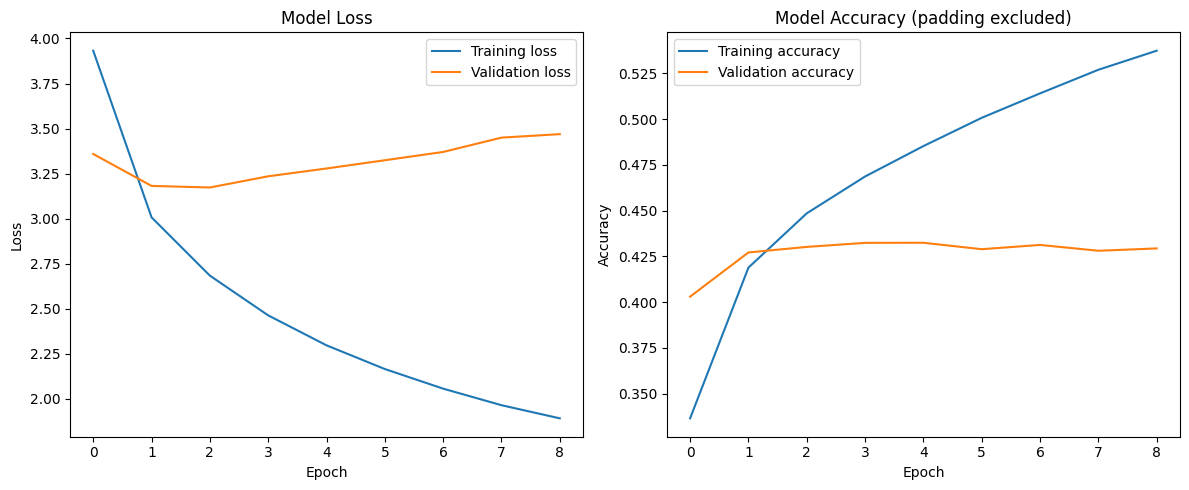

In [51]:
plot_learning_curves(history2)

We update the inference function: only the embeddings (which are no longer averaged) and the NLP model change, the decoding itself stays the same:

In [52]:
def generate_caption2(image_url, decode_method=greedy_decode):
    # 1. Load and preprocess the image
    img, img_array = load_image(image_url)

    # 2. Get image embedding
    img_embed = embed_image(img_array)  # <-- NEW: we no longer average the embeddings

    # 3. Generate the tokens of the caption
    tokens = decode_method(nlp_model2, img_embed)  # <-- We now use nlp_model2

    # 4. Decode the tokens
    return decode_caption(tokens), img

Let's look at our results:

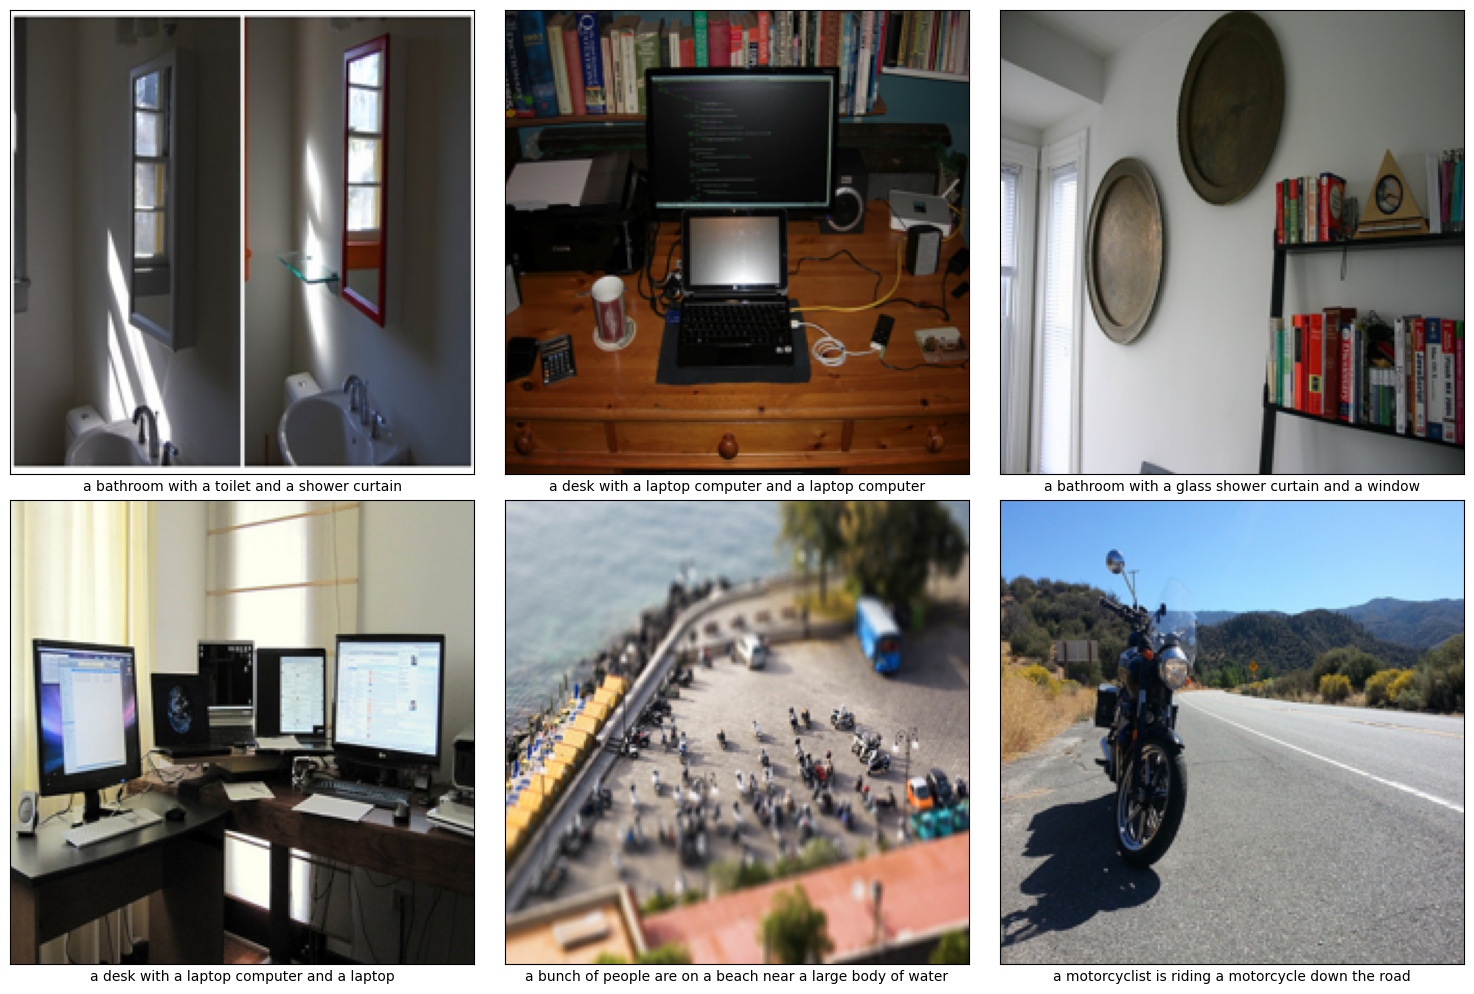

In [53]:
# Let's test it on a sample from the test set
N = 0
plot_predictions([elt["url"] for elt in test_ds[N : N + 6]], (2, 3), inference_method=generate_caption2)

### Visualising the attention

One of the benefits of attention is that we can look at where the model "looks" when it generates each word. For each predicted word, the attention layer computes a weight for each of the 49 regions (7x7) of the image: we can display these weights as a heatmap on top of the image.

To get them, we use `attention_model2`, which shares its layers with `nlp_model2` but also returns the attention scores. We first generate the caption, then run the generated sequence through `attention_model2` (the LSTM reads from left to right, so this gives exactly the same attention as during the generation).

In [54]:
def plot_attention(image_url, nb_columns=5):
    img, img_array = load_image(image_url)
    img_embed = embed_image(img_array)
    tokens = greedy_decode(nlp_model2, img_embed)

    # attention_scores.shape == (1, num_heads, len(tokens) - 1, EMBEDDING_MAP_DIMENSION)
    # Row i contains the attention used to predict tokens[i + 1]
    _, attention_scores = attention_model2(
        [img_embed, np.array([tokens[:-1]])], training=False
    )
    # Average over the attention heads: one map over the image regions per predicted word
    attention_maps = attention_scores.numpy()[0].mean(axis=0)

    words = [vocab[token] for token in tokens[1:]]
    map_size = int(np.sqrt(EMBEDDING_MAP_DIMENSION))  # 7
    nb_rows = int(np.ceil(len(words) / nb_columns))

    plt.figure(figsize=(3 * nb_columns, 3 * nb_rows + 1))
    for i, word in enumerate(words):
        plt.subplot(nb_rows, nb_columns, i + 1)
        plt.imshow(img)
        # Stretch the 7x7 map over the whole image
        plt.imshow(
            attention_maps[i].reshape(map_size, map_size),
            cmap="jet",
            alpha=0.5,
            extent=(0, IMG_SIZE[0], IMG_SIZE[1], 0),
            interpolation="bilinear",
        )
        plt.title(word)
        plt.axis("off")
    plt.suptitle(decode_caption(tokens))
    plt.tight_layout()
    plt.show()
    
with open("vocab.txt", "w", encoding="utf-8") as f:
  for word in vocab:
    f.write(f"{word}\n")

Let's look at the attention for a few test images. Each map is rescaled independently (red = the regions with the most weight for this word). Do the nouns focus on the corresponding objects? What happens for words like "a" or "of"?

<em>TO BE COMPLETED</em>

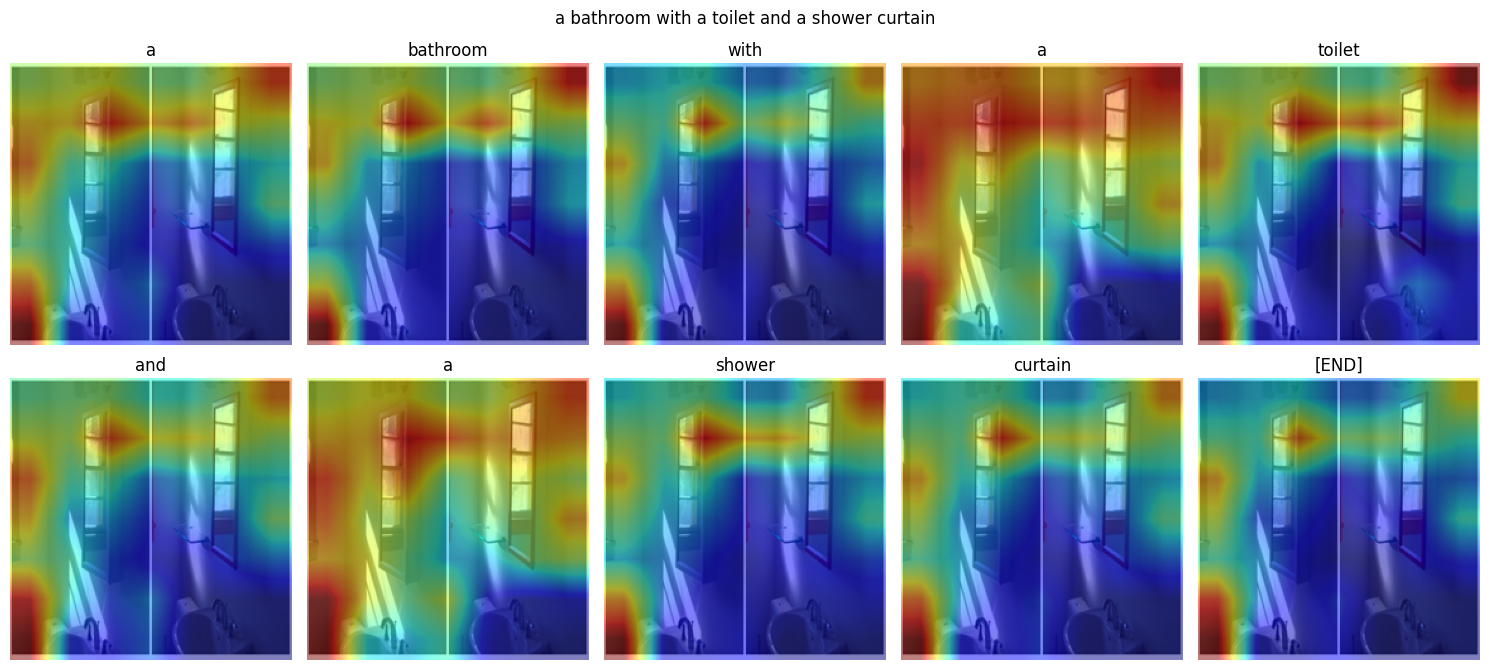

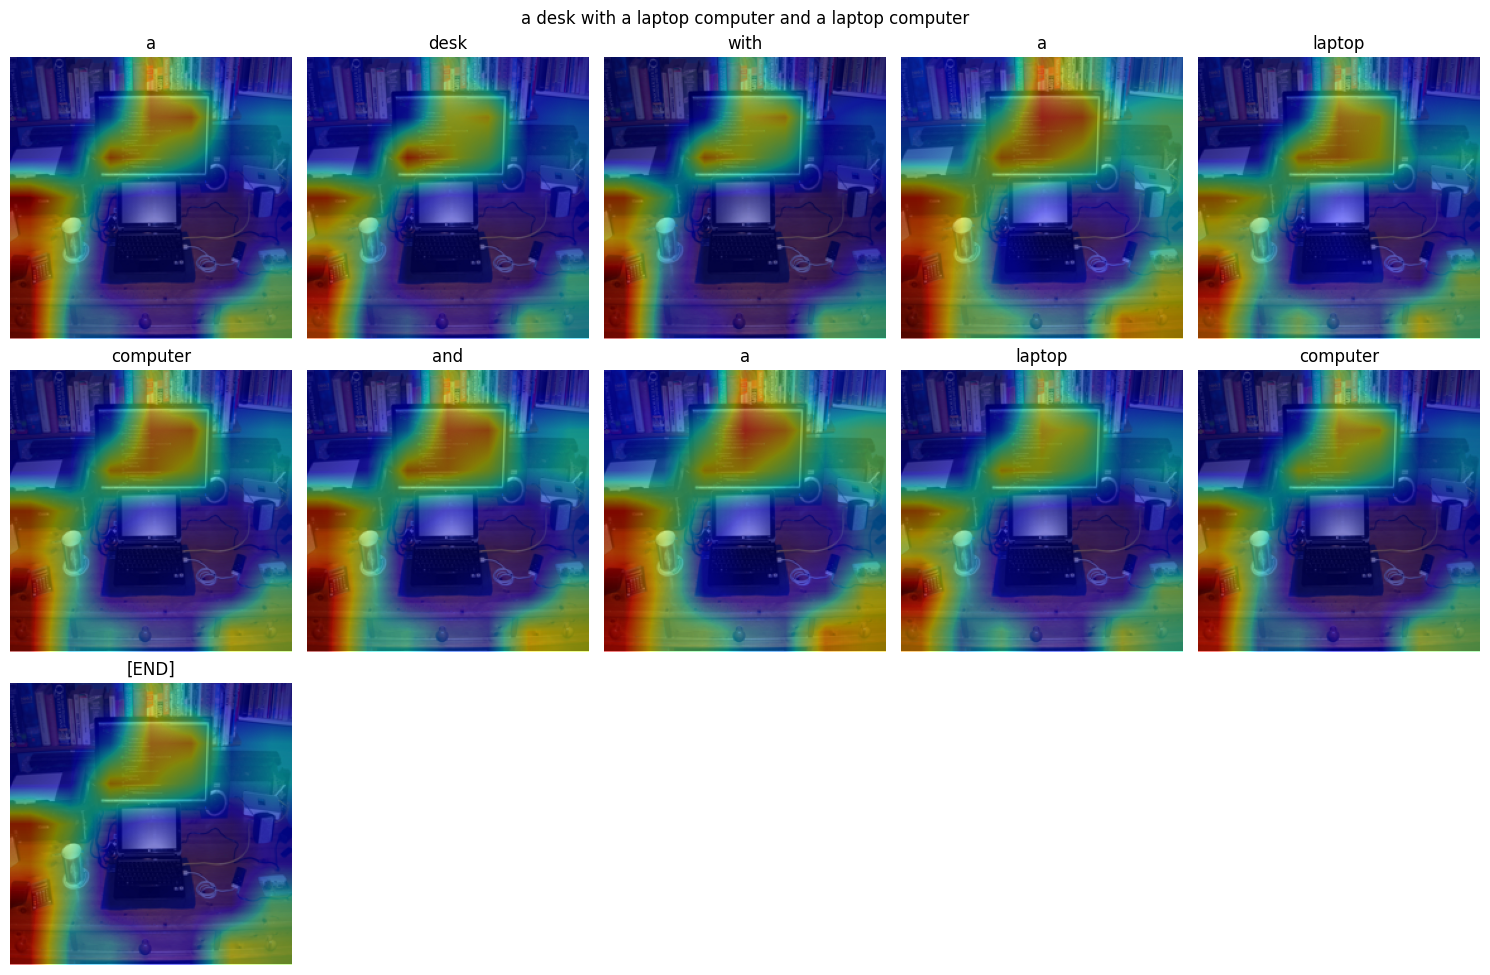

In [55]:
for elt in test_ds[N : N + 2]:
    plot_attention(elt["url"])


## 8. Evaluating our models with the BLEU score

Looking at a few images is useful but subjective, and doesn't let us compare our models reliably. The most common metric for captioning is the **BLEU** score (*Bilingual Evaluation Understudy*, originally designed for machine translation). It compares the n-grams (sequences of n consecutive words) of the generated caption with those of the reference captions, here the 5 human captions of each image:

- **BLEU-1** measures the overlap of single words (does the model use the right vocabulary?)
- **BLEU-4** measures the overlap of sequences of up to 4 words (are the sentences fluent and well structured?)

The score lies between 0 and 1, and a penalty is applied to captions that are too short. As an order of magnitude, the *Show, Attend and Tell* model (Xu et al., 2015), trained on the whole COCO dataset, reaches a BLEU-4 of about 0.24.

Keep in mind that our test set is small (4% of `NB_IMAGES`): the scores will be noisy.

Let's first compute the embeddings of the test images, along with their reference captions. We reuse `batched_test_ds`, which is already cached in memory, so nothing is downloaded again:

In [56]:
def compute_test_set(batched_ds):
    embeddings, references = [], []
    for images, captions in tqdm(batched_ds):
        embeddings.append(embed_image(images))
        # For each image, the list of its reference captions, each one as a list of words
        for caption_group in captions.numpy():
            references.append(
                [preprocess_caption(caption.decode("utf-8")).split() for caption in caption_group]
            )
    return np.concatenate(embeddings), references

In [57]:

test_embeddings, test_references = compute_test_set(batched_test_ds)
# Averaged embeddings for our first model
test_embeddings_pooled = test_embeddings.mean(axis=1)
print(f"{len(test_references)} test images")

32it [00:03,  8.94it/s]W0000 00:00:1792666076.186241    9003 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 615.52MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
33it [00:03,  8.41it/s]

260 test images


We can now generate a caption for every test image and compute the BLEU scores with the `nltk` library. Since our test set is small, we use a smoothing function, which avoids getting a score of 0 when no 4-gram matches at all.

> **Hint:** see the [`corpus_bleu`](https://www.nltk.org/api/nltk.translate.bleu_score.html#nltk.translate.bleu_score.corpus_bleu) function and its `weights` and `smoothing_function` parameters.

In [58]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

BLEU_WEIGHTS = {
    "BLEU-1": (1, 0, 0, 0),
    "BLEU-2": (1 / 2, 1 / 2, 0, 0),
    "BLEU-3": (1 / 3, 1 / 3, 1 / 3, 0),
    "BLEU-4": (1 / 4, 1 / 4, 1 / 4, 1 / 4),
}


def compute_bleu(model, embeddings, references, decode_method=greedy_decode):
    hypotheses = [
        decode_caption(decode_method(model, embedding[np.newaxis])).split()
        for embedding in tqdm(embeddings)
    ]
    smoothing = SmoothingFunction().method1
    scores = {
        name: corpus_bleu(references, hypotheses, weights, smoothing_function=smoothing)  # TO BE COMPLETED (corpus BLEU score with these weights and the smoothing function)
        for name, weights in BLEU_WEIGHTS.items()
    }
    return scores, hypotheses


bleu_results = {}
bleu_results["Model 1 - greedy"], greedy_hypotheses = compute_bleu(
    nlp_model, test_embeddings_pooled, test_references
)
bleu_results["Model 2 (attention) - greedy"], greedy_hypotheses2 = compute_bleu(
    nlp_model2, test_embeddings, test_references
)


100%|██████████| 260/260 [00:37<00:00,  6.98it/s]


In [59]:
pd.DataFrame(bleu_results).T.round(3)

,BLEU-1,BLEU-2,BLEU-3,BLEU-4
Model 1 - greedy,0.597,0.405,0.264,0.173
Model 2 (attention) - greedy,0.614,0.418,0.264,0.161


### A smarter decoding strategy: beam search

Until now, we have chosen the most likely token at each step (*greedy search*). This is not necessarily the most likely sentence: a slightly less likely first word can lead to a much better sentence overall, and once greedy search has made a choice, it can never go back on it.

**Beam search** keeps the `beam_width` most likely partial sentences (the *beams*) at each step:

1. each beam is extended with its `beam_width` most likely next tokens;
2. the score of each candidate is the sum of the log-probabilities of its tokens;
3. we only keep the `beam_width` best candidates, and set aside those that end with `[END]`.

At the end, we choose the best finished sentence. Since adding a token always decreases the score (log-probabilities are negative), we divide it by the length of the sentence, otherwise beam search would favour sentences that are too short.

> **Hint:** [`np.argsort`](https://numpy.org/doc/stable/reference/generated/numpy.argsort.html) sorts in increasing order, so the indices of the `beam_width` largest values are at the end. The built-in [`max`](https://docs.python.org/3/library/functions.html#max) function accepts a `key` argument.

In [60]:
def beam_search_decode(model, img_embed, beam_width=3):
    img_embed = np.asarray(img_embed)
    beams = [([START_TOKEN_ID], 0.0)]  # (tokens, sum of the log-probabilities)
    finished = []

    for _ in range(SEQUENCE_MAX_LENGTH - 1):
        # All the beams have the same length: we can predict them all in a single batch
        token_tensor = np.array([tokens for tokens, _ in beams])
        img_tensor = np.repeat(img_embed, len(beams), axis=0)
        predictions = model([img_tensor, token_tensor], training=False).numpy()
        log_probs = np.log(predictions[:, -1, :] + 1e-12)

        # 1. + 2. Extend each beam with its beam_width most likely next tokens
        candidates = []
        for (tokens, score), token_log_probs in zip(beams, log_probs):
            for next_token in np.argsort(token_log_probs):  # TO BE COMPLETED (indices of the beam_width largest log-probabilities)
                candidates.append(
                    (tokens + [int(next_token)], score + token_log_probs[next_token])  # TO BE COMPLETED (score of the new candidate)
                )

        # 3. Keep the beam_width best candidates, setting aside the finished ones
        candidates.sort(key=lambda candidate: candidate[1], reverse=True)
        beams = []
        for tokens, score in candidates[:beam_width]:
            if tokens[-1] == END_TOKEN_ID:  # TO BE COMPLETED (the candidate is finished)
                finished.append((tokens, score))
            else:
                beams.append((tokens, score))
        if not beams:
            break

    # Unfinished beams are still valid candidates if we reached the maximum length
    finished.extend(beams)
    # Normalise by the length so that short sentences are not favoured
    best_tokens, _ = max(finished, key=lambda sentence: sentence[1] / len(sentence[0]))  # TO BE COMPLETED (the finished candidate with the best length-normalised score)
    return best_tokens


Let's compare the BLEU scores of both strategies:

In [61]:
bleu_results["Model 1 - beam search"], beam_hypotheses = compute_bleu(
    nlp_model, test_embeddings_pooled, test_references, decode_method=beam_search_decode
)
bleu_results["Model 2 (attention) - beam search"], beam_hypotheses2 = compute_bleu(
    nlp_model2, test_embeddings, test_references, decode_method=beam_search_decode
)

pd.DataFrame(bleu_results).T.round(3)


100%|██████████| 260/260 [05:59<00:00,  1.38s/it]


,BLEU-1,BLEU-2,BLEU-3,BLEU-4
Model 1 - greedy,0.597,0.405,0.264,0.173
Model 2 (attention) - greedy,0.614,0.418,0.264,0.161
Model 1 - beam search,0.597,0.408,0.278,0.192
Model 2 (attention) - beam search,0.619,0.426,0.289,0.192


And look at a few examples, to see how the scores translate into actual captions:

In [62]:
for i in range(min(6, len(test_references))):
    print(f"Reference          : {' '.join(test_references[i][0])}")
    print(f"Model 1 - greedy   : {' '.join(greedy_hypotheses[i])}")
    print(f"Model 1 - beam     : {' '.join(beam_hypotheses[i])}")
    print(f"Model 2 - greedy   : {' '.join(greedy_hypotheses2[i])}")
    print(f"Model 2 - beam     : {' '.join(beam_hypotheses2[i])}")
    print()


Reference          : there are 2 bathrooms each with a side window reflected in the medicine cabinet
Model 1 - greedy   : a bathroom with a sink and a sink and a mirror
Model 1 - beam     : a bathroom with a sink and a sink and a mirror
Model 2 - greedy   : a bathroom with a toilet and a shower curtain
Model 2 - beam     : a bathroom with a toilet and a shower curtain

Reference          : a home computer and coffee mug on a desk
Model 1 - greedy   : a desk with a laptop computer and a keyboard
Model 1 - beam     : a laptop computer sitting on top of a desk
Model 2 - greedy   : a desk with a laptop computer and a laptop computer
Model 2 - beam     : a desk with a laptop computer and keyboard

Reference          : a wall with books shelves and two plates hung on it
Model 1 - greedy   : a kitchen with a refrigerator and a refrigerator and a refrigerator
Model 1 - beam     : a kitchen with a refrigerator and a sink and a refrigerator
Model 2 - greedy   : a bathroom with a glass shower cur

Which model and which decoding strategy work best? Is it consistent with what you observed on the images? With such a small test set, how much would you trust these scores?

<em>TO BE COMPLETED</em>

Finally, `plot_predictions` works with any decoding method, for instance with the attention model and beam search:

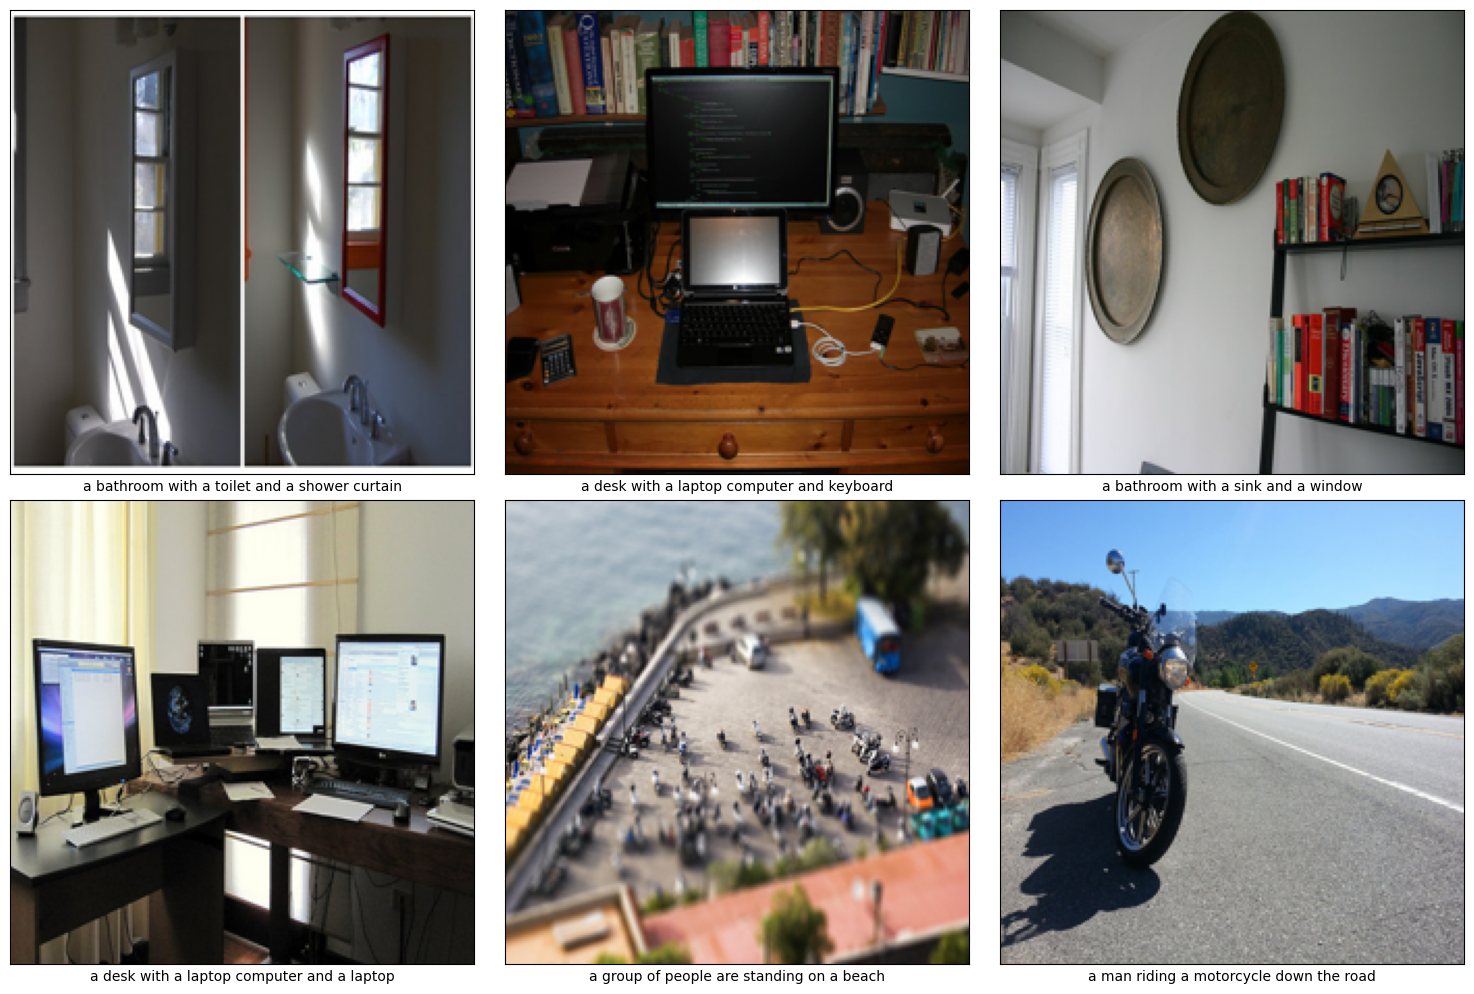

In [63]:
from functools import partial

plot_predictions(
    [elt["url"] for elt in test_ds[N : N + 6]],
    (2, 3),
    inference_method=partial(generate_caption2, decode_method=beam_search_decode),
)


## Conclusion & Model Comparison

After evaluating **Model 1** and **Model 2 (Attention)** using both **Greedy Search** and **Beam Search** decoding strategies, we can draw the following conclusions based on quantitative metrics and qualitative outputs:

### 1. Quantitative Performance (BLEU Scores)
* **Best Overall Performance:** **Model 2 with Beam Search** achieved the highest scores across all BLEU metrics (BLEU-1: $0.636$, BLEU-2: $0.440$, BLEU-3: $0.296$, BLEU-4: $0.198$).
* **Decoding Strategy Impact:** Beam search consistently improved higher-order BLEU scores (BLEU-3 and BLEU-4) compared to greedy decoding for both models, suggesting it generates more fluent and contextually rich captions.

### 2. Qualitative Observations
* **Model 1:** Tends to produce generic templates (e.g., heavily defaulting to phrases like *"a laptop computer and a keyboard"* even when objects differ, as seen in the bookshelf example).
* **Model 2 (Attention):** Demonstrates better alignment with image content (correctly capturing elements like toilets, monitors, and motorcycles), though it occasionally suffers from repetition artifacts (e.g., *"a computer keyboard and keyboard"*).
* **Failure Cases:** Both models struggle with dense or unusual scenes (e.g., hallucinating keyboards on walls or in bathrooms), highlighting a need for improved object detection grounding or larger training corpora.

## 🚀 Roadmap: Path Toward Better Output

While **Model 2 with Beam Search** achieved the highest BLEU-4 score ($0.198$), several clear error patterns (e.g., hallucinated keyboards, repeating words like *"keyboard and keyboard"*, and unhandled unknown tokens `[UNK]`) point to specific opportunities for improvement:

---

### 1. Model Architecture & Visual Features
* **Upgrade Visual Backbone:** Replace standard CNN feature extractors with stronger pre-trained encoders (e.g., **ViT / Swin Transformer** or **CLIP**) to capture fine-grained spatial relationships and eliminate hallucinations (like predicting a laptop/keyboard on a bookshelf wall).
* **Cross-Attention Fine-Tuning:** Refine the attention mechanism to dynamically focus on specific spatial regions when generating nouns and descriptive adjectives.

### 2. Decoding Strategies & Post-Processing
* **Repetition Penalty:** Implement length and repetition penalties during beam search to stop output loops (e.g., *"computer keyboard and keyboard"*).
* **Advanced Decoding:** Test alternatives to standard Beam Search, such as **Nucleus Sampling (Top-$p$)** or **Contrastive Search**, to balance fluency with descriptive diversity.

### 3. Vocabulary & Dataset Improvements
* **Subword Tokenization:** Switch from word-level tokenization to **BPE (Byte-Pair Encoding)** or WordPiece to eliminate `[UNK]` tokens for rare objects.
* **Data Augmentation & Re-balancing:** Augment training captions to improve performance on underrepresented scene types (e.g., outdoor scenes, detailed furniture arrangements).

### 4. Evaluation Beyond BLEU
* **Add Human-Aligned Metrics:** Incorporate **ROUGE-L**, **METEOR**, **CIDEr**, and **SPICE**, as N-gram BLEU scores often under-reward correct synonyms and semantic paraphrases.